# Presentación: Analítica predictiva sobre la base de muestras de un laboratorio de microbiología

Versión corta para la exposición de diez minutos: once diapositivas con las cifras que ya calcularon los
notebooks de las etapas y, entre ellas, los fragmentos de código que muestran cómo se hizo cada paso (las mismas
llamadas al paquete `proyecto/`). Aquí no se repite el cálculo pesado: los arreglos pequeños que usan los
fragmentos y las animaciones se prepararon al construir el notebook. El detalle completo está en
`Proyecto_Final.ipynb`.

## Código del proyecto

La celda siguiente vuelve a crear el paquete `proyecto/` dentro de la sesión. Así el notebook funciona en Google Colab sin clonar ningún repositorio: Basta con ejecutarla una vez (*Entorno de ejecución → Ejecutar todas*). En una copia local del repositorio no reemplaza ningún archivo y la sección se puede plegar desde su título. Trae también los artefactos pequeños que leen las diapositivas (JSON, arreglos y el modelo de regresión), así que no hace falta volver a ejecutar las etapas.

In [ ]:
# Código del proyecto. Esta celda recrea en el directorio de trabajo:
#   - el paquete `proyecto/` (55 módulos) y `configuracion/mapeo_columnas.json`;
#   - los 21 artefactos pequeños que lee la presentación;
# para que el notebook funcione en Google Colab sin clonar el repositorio. Todo viaja
# al final de la celda como un .tar.xz en base64 (87 archivos, 1416 kB).
# Antes de extraer se comprueba su huella SHA-256. Un archivo que ya existe con el
# mismo contenido no se toca, y uno que existe con otro contenido (una copia local
# del repositorio con cambios, por ejemplo) se conserva y se avisa; para
# reemplazarlo hay que poner SOBRESCRIBIR = True.
import base64
import hashlib
import importlib
import io
import os
import sys
import tarfile
from pathlib import Path

SOBRESCRIBIR = False


def recrear_proyecto(huella, codificado):
    datos = base64.b64decode(codificado)
    if hashlib.sha256(datos).hexdigest() != huella:
        raise ValueError("El código embebido está dañado: su SHA-256 no coincide.")
    escritos, iguales, conservados = 0, 0, []
    with tarfile.open(fileobj=io.BytesIO(datos), mode="r:xz") as archivo:
        for miembro in archivo.getmembers():
            nombre = miembro.name
            if Path(nombre).is_absolute() or ".." in Path(nombre).parts:
                raise ValueError(f"Ruta no permitida en el archivo: {nombre}")
            contenido, destino = archivo.extractfile(miembro).read(), Path(nombre)
            if destino.exists() and destino.read_bytes() == contenido:
                iguales += 1
            elif destino.exists() and not SOBRESCRIBIR:
                conservados.append(nombre)
            else:
                destino.parent.mkdir(parents=True, exist_ok=True)
                destino.write_bytes(contenido)
                escritos += 1
    if os.getcwd() not in sys.path:
        sys.path.insert(0, os.getcwd())
    importlib.invalidate_caches()
    print(f"Código del proyecto: {escritos} archivos escritos, {iguales} ya estaban iguales.")
    if conservados:
        print(f"Se conservaron {len(conservados)} archivos locales distintos:", ", ".join(conservados))


recrear_proyecto(
    huella="a71404d3889bd9b09bc8d1675a65808dad59a3a4e4ef691a103abbaba3d814af",
    codificado="...",
)

## Diapositivas

In [1]:
from proyecto.base.salida import mostrar
from proyecto.etapas import presentacion as p
from proyecto.reporte import graficos_presentacion as g
from proyecto.reporte import interactivo as ui   # paneles con controles para la exposición en vivo
from proyecto.reporte.figuras import mostrar_figura

d = p.iniciar()   # estilo editorial y arreglos pequeños calculados al construir (sin la partición de prueba)

In [2]:
p.diapositiva_portada().mostrar()

In [3]:
p.diapositiva_problema().mostrar()

In [4]:
p.diapositiva_datos().mostrar()

**Cómo se valida sin mirar el futuro.** La validación cruzada no baraja las filas: cada bloque se ajusta con el
pasado y se valida con el tramo que sigue, y el periodo de validación y el de prueba quedan después de todos ellos.

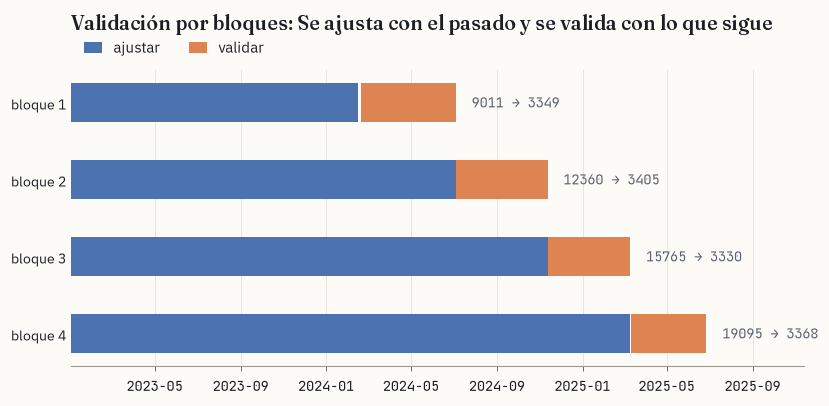

In [5]:
import pandas as pd
from proyecto.evaluacion import validacion

fechas = pd.Series(d.fechas_entrenamiento)        # fecha de recepción de cada muestra de entrenamiento
bloques = validacion.bloques_temporales(fechas)   # índices (ajustar, validar) que se pasan como cv= a scikit-learn
mostrar_figura(g.figura_bloques(fechas, bloques))

In [6]:
p.diapositiva_exploracion().mostrar()

In [7]:
p.diapositiva_metodo().mostrar()

In [8]:
from proyecto.cribado import arreglos
from proyecto.reporte.html import tabla_html

l16 = arreglos.arreglo_l16()                        # 16 corridas: A con 4 niveles y doce columnas de 2 niveles
ortogonal = arreglos.verificar_ortogonalidad(l16)   # cada par de columnas aparece balanceado
titulo = f"Arreglo ortogonal L16 (ortogonalidad verificada: {'sí' if ortogonal else 'no'})"
mostrar(tabla_html(l16, titulo, decimales=0, maximo_filas=16))

A,c,ac,bc,abc,d,ad,bd,abd,cd,acd,bcd,abcd
0,0,0,0,0,0,0,0,0,0,0,0,0
0,0,0,0,0,1,1,1,1,1,1,1,1
0,1,1,1,1,0,0,0,0,1,1,1,1
0,1,1,1,1,1,1,1,1,0,0,0,0
1,0,0,1,1,0,0,1,1,0,0,1,1
1,0,0,1,1,1,1,0,0,1,1,0,0
1,1,1,0,0,0,0,1,1,1,1,0,0
1,1,1,0,0,1,1,0,0,0,0,1,1
2,0,1,0,1,0,1,0,1,0,1,0,1
2,0,1,0,1,1,0,1,0,1,0,1,0


In [9]:
p.diapositiva_regresion().mostrar()

**El modelo de la carga diaria** es una regresión lineal sobre retrasos, medias móviles, calendario y agenda; su
habilidad compara el error con el de la mejor referencia ingenua:

$$\hat y_{t+1} = {\color{#3B64A8}{\beta_0}} + \sum_j {\color{#3B64A8}{\beta_j}}\, x_{t,j}
\qquad\qquad \text{habilidad} = 1 - \frac{{\color{#B8423F}{\mathrm{RMSE}_{\text{modelo}}}}}{\mathrm{RMSE}_{\text{referencia}}}$$

El modelo congelado se guarda en disco y se usa así (los días de la tabla son de validación, que el reajuste
final ya vio: la celda muestra la llamada, el error se midió en prueba):

In [10]:
import joblib
from proyecto.base import rutas

modelo = joblib.load(rutas.DIR_ARTEFACTOS / "modelos" / "regresion.joblib")   # congelado en la etapa 04
r = d.regresion
dias = r.dias.assign(predicción=modelo.predict(r.dias[r.variables]))
mostrar(tabla_html(dias[[r.fecha, r.objetivo, "predicción"]], "Modelo congelado: muestras por día", decimales=1))

fecha,muestras_dia,predicción
2025-12-17,44,43.9
2025-12-18,53,53.2
2025-12-19,20,36.1
2025-12-22,28,56.5
2025-12-23,10,42.9
2025-12-24,37,36.3
2025-12-26,53,64.6
2025-12-29,48,64.3
2025-12-30,38,40.4
2025-12-31,22,25.3


In [11]:
p.diapositiva_clasificacion().mostrar()

**Del riesgo a la alerta.** La regresión logística da una probabilidad, y la alerta se dispara cuando supera el
umbral ${\color{#C46A2B}{t}}$, elegido en validación por costo: perder una no conforme (FN) cuesta más que una falsa
alarma (FP).

$$p(x) = \sigma\big({\color{#6E5BA8}{\beta_0 + \beta^\top x}}\big)
\qquad\qquad
\text{Costo}({\color{#C46A2B}{t}}) = c_{FP}\,{\color{#6B6B6B}{FP(t)}} + c_{FN}\,{\color{#B8423F}{FN(t)}}$$

La tubería se arma con una sola llamada; scikit-learn la dibuja paso a paso:

In [12]:
from proyecto.modelos import tuberias

clf = p.artefacto("05_clasificacion")
cfg = clf["configuracion"]                           # lo que eligieron el L16, la rejilla y la validación
tuberia = tuberias.construir_tuberia(
    "clasificacion", cfg["modelo"], d.numericas, d.categoricas, escalado=cfg["escalado"],
    codificacion=cfg["codificacion"], seleccion=cfg["seleccion"], desbalance=cfg["desbalance"])
mostrar(tuberia)

,steps,"[('preparar', ...), ('seleccionar', ...), ...]"
,transform_input,None
,memory,None
,verbose,False
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('numericas', ...), ('categoricas', ...)]"
,"verbose_feature_names_out verbose_feature_names_out: bool, str or Callable[[str, str], str], default=True- If True, :meth:`ColumnTransformer.get_feature_names_out` will prefix all feature names with the name of the transformer that generated that feature. It is equivalent to setting `verbose_feature_names_out=""{transformer_name}__{feature_name}""`.- If False, :meth:`ColumnTransformer.get_feature_names_out` will not prefix any feature names and will error if feature names are not unique.- If ``Callable[[str, str], str]``, :meth:`ColumnTransformer.get_feature_names_out` will rename all the features using the name of the transformer. The first argument of the callable is the transformer name and the second argument is the feature name. The returned string will be the new feature name.- If ``str``, it must be a string ready for formatting. The given string will be formatted using two field names: ``transformer_name`` and ``feature_name``. e.g. ``""{feature_name}__{transformer_name}""``. See :meth:`str.format` method from the standard library for more info... versionadded:: 1.0.. versionchanged:: 1.6 `verbose_feature_names_out` can be a callable or a string to be formatted.",False
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transformers contains sparse matrices,these will be stacked as a sparse matrix if the overall density islower than this value. Use ``sparse_threshold=0`` to always returndense. When the transformed output consists of all dense data, thestacked result will be dense, and this keyword will be ignored.",0.3
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.",No


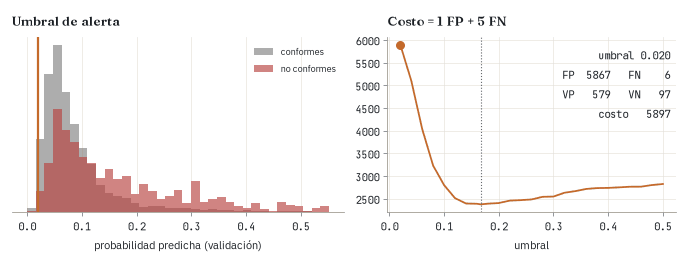
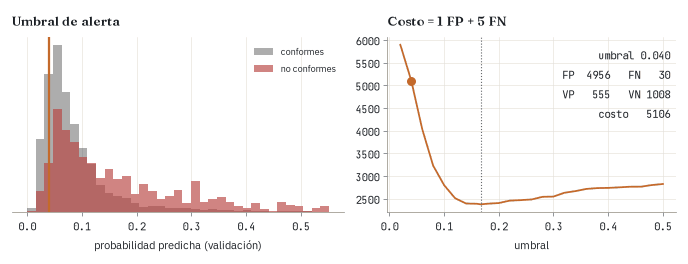
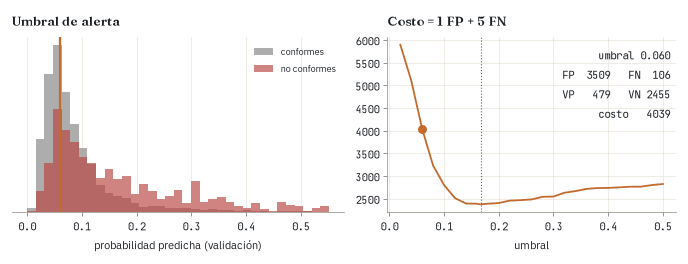
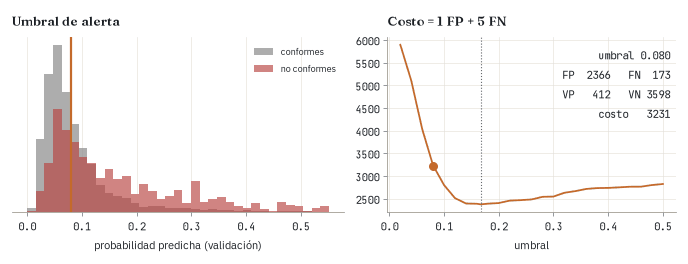
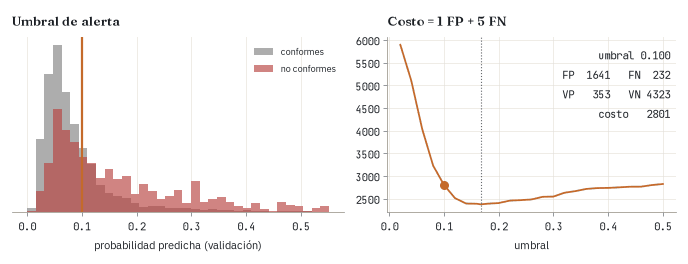
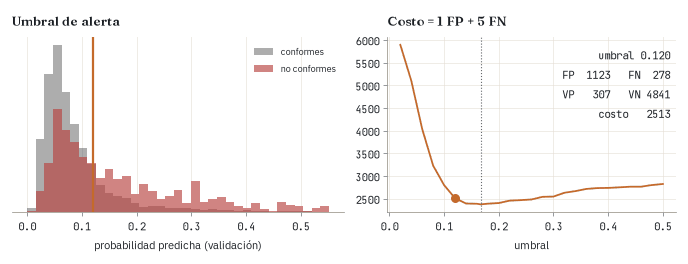
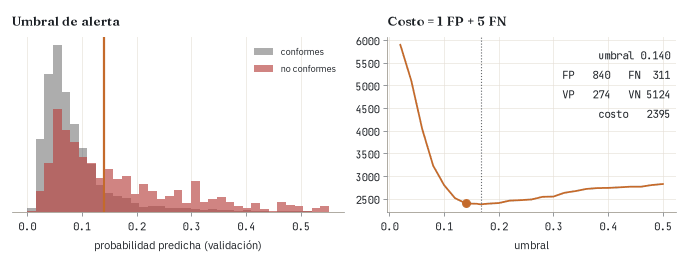
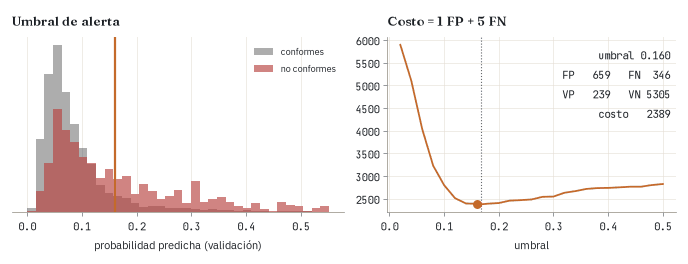
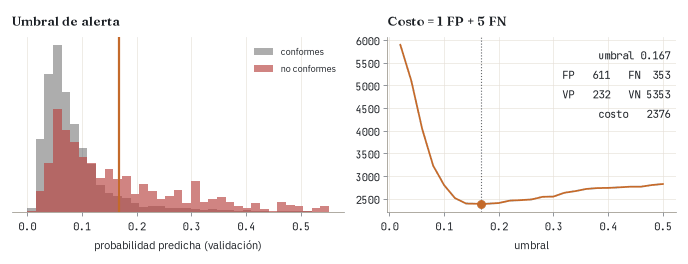
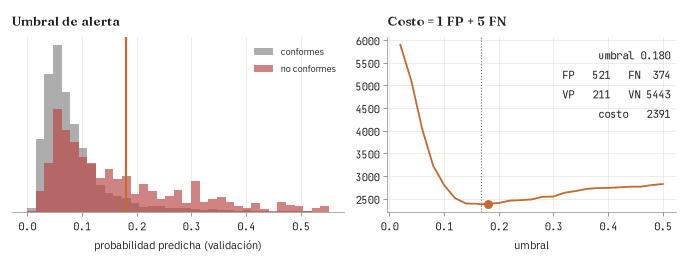
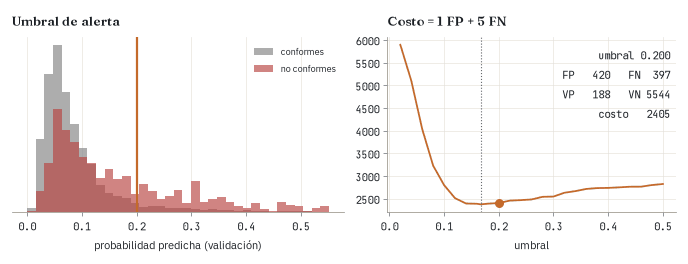
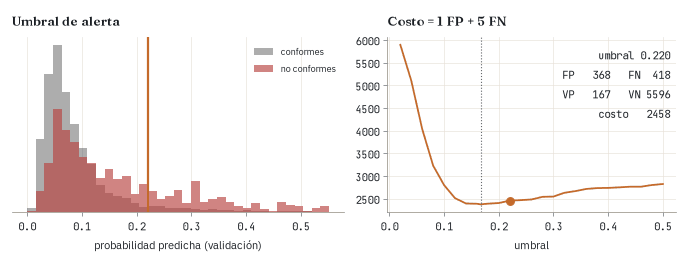
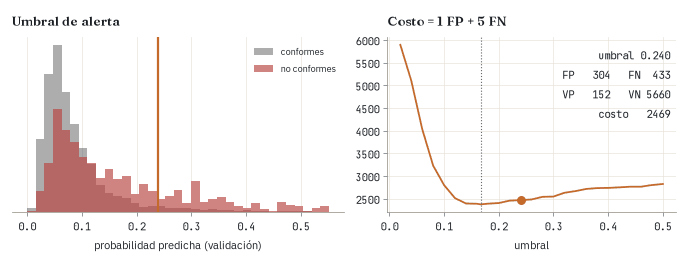
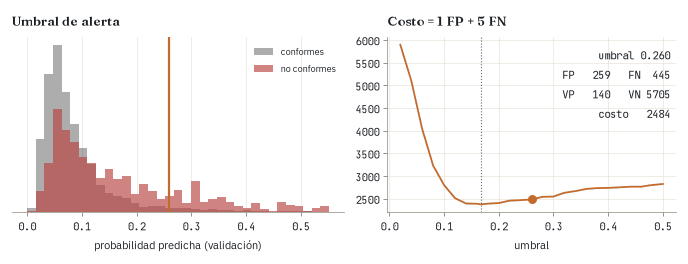
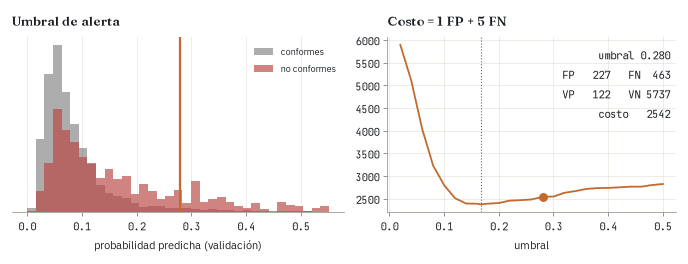
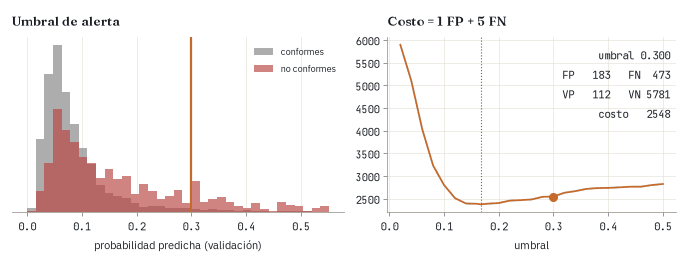
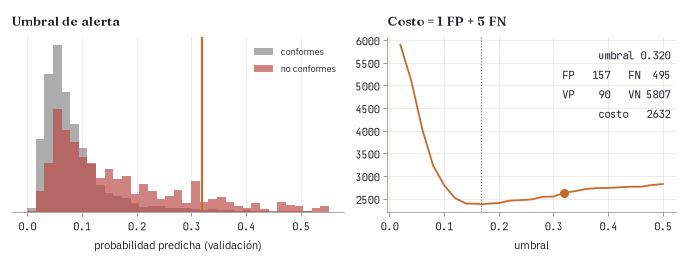
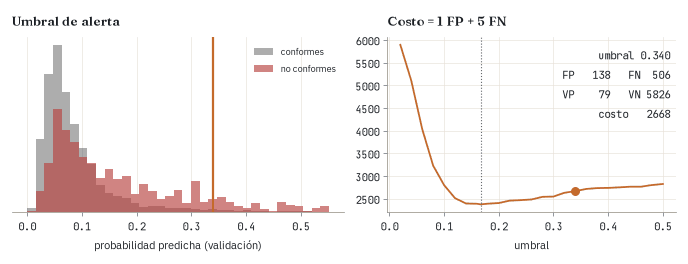
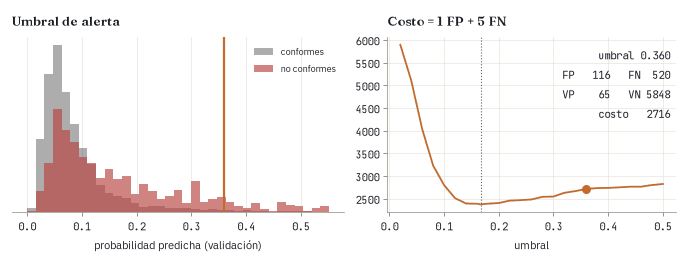
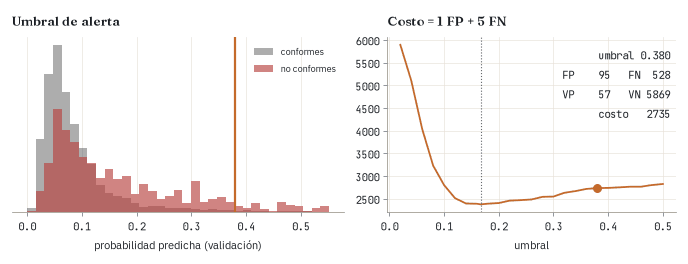
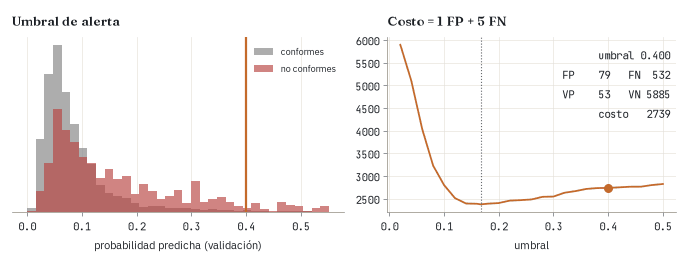
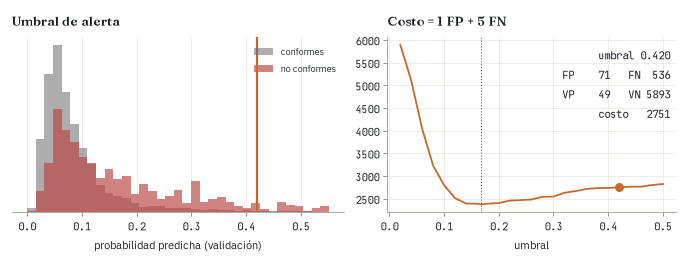
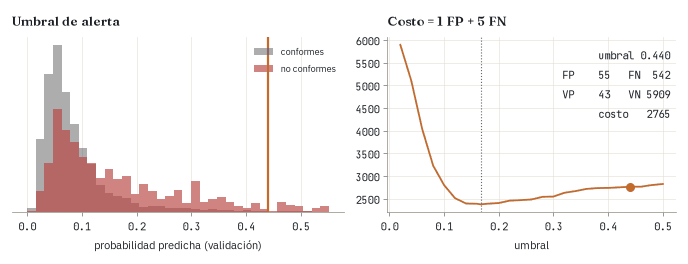
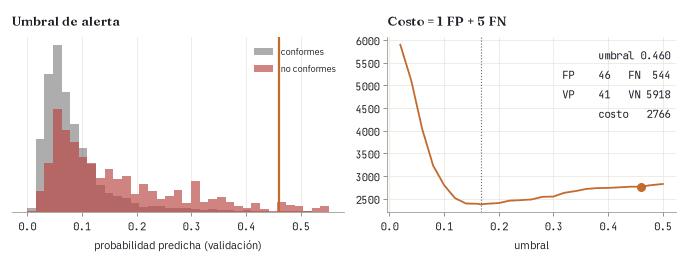
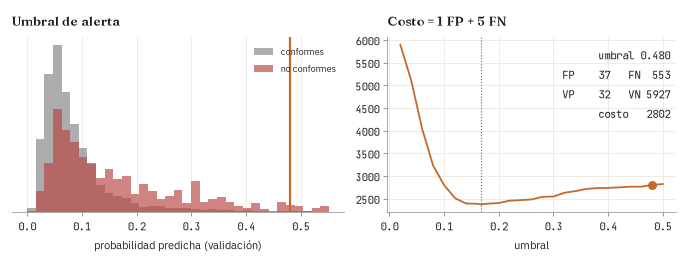
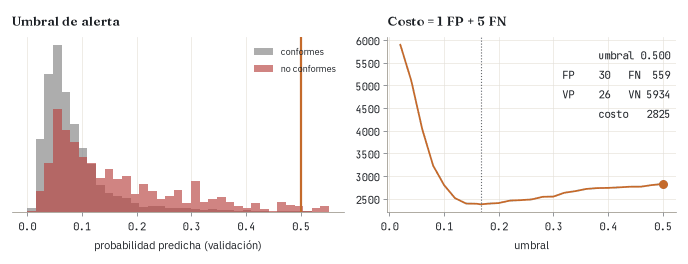

In [13]:
umbrales = [u["Umbral"] for u in clf["tabla_umbrales"]]   # el mismo recorrido de la etapa 05
costos = clf["costos"]
animacion = g.animacion_umbral(d.proba_validacion, d.y_validacion, umbrales,
                               costos["falso_positivo"], costos["falso_negativo"], clf["umbral"])
mostrar(animacion)

Panel interactivo: Ejecute la celda con el núcleo en marcha para mover los controles.

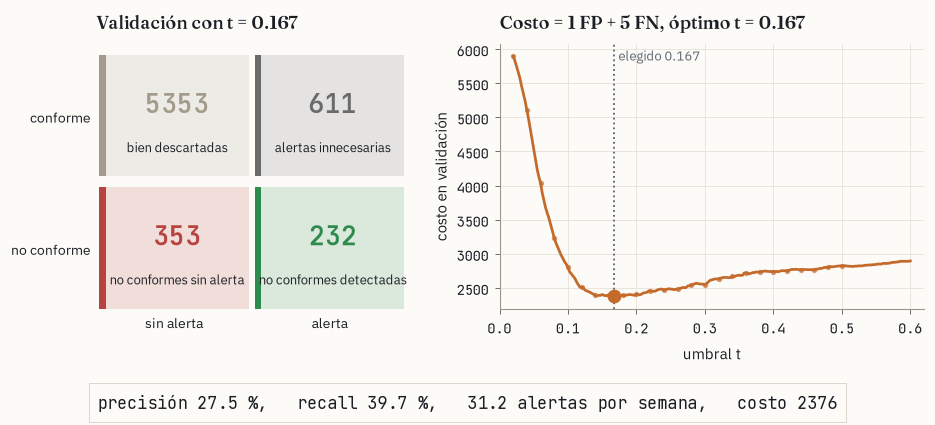

In [14]:
mostrar(ui.panel_umbral(d))   # mueva el umbral: precisión, recall, alertas por semana y costo

Panel interactivo: Ejecute la celda con el núcleo en marcha para mover los controles.

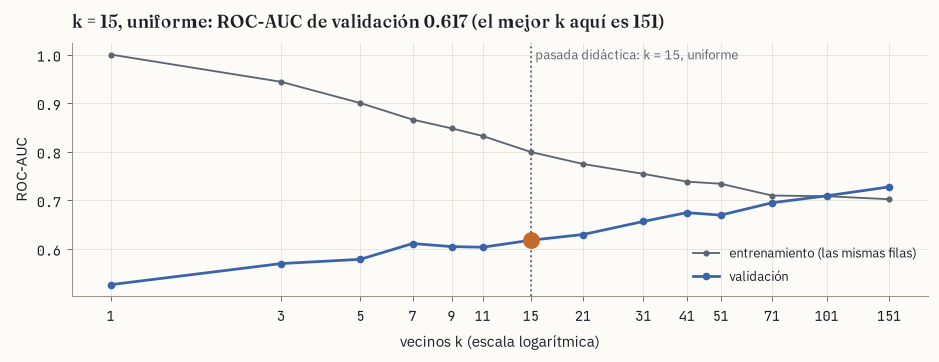

In [15]:
mostrar(ui.panel_knn(d))      # vecinos k: sobreajuste con k pequeño, subajuste con k grande

Panel interactivo: Ejecute la celda con el núcleo en marcha para mover los controles.

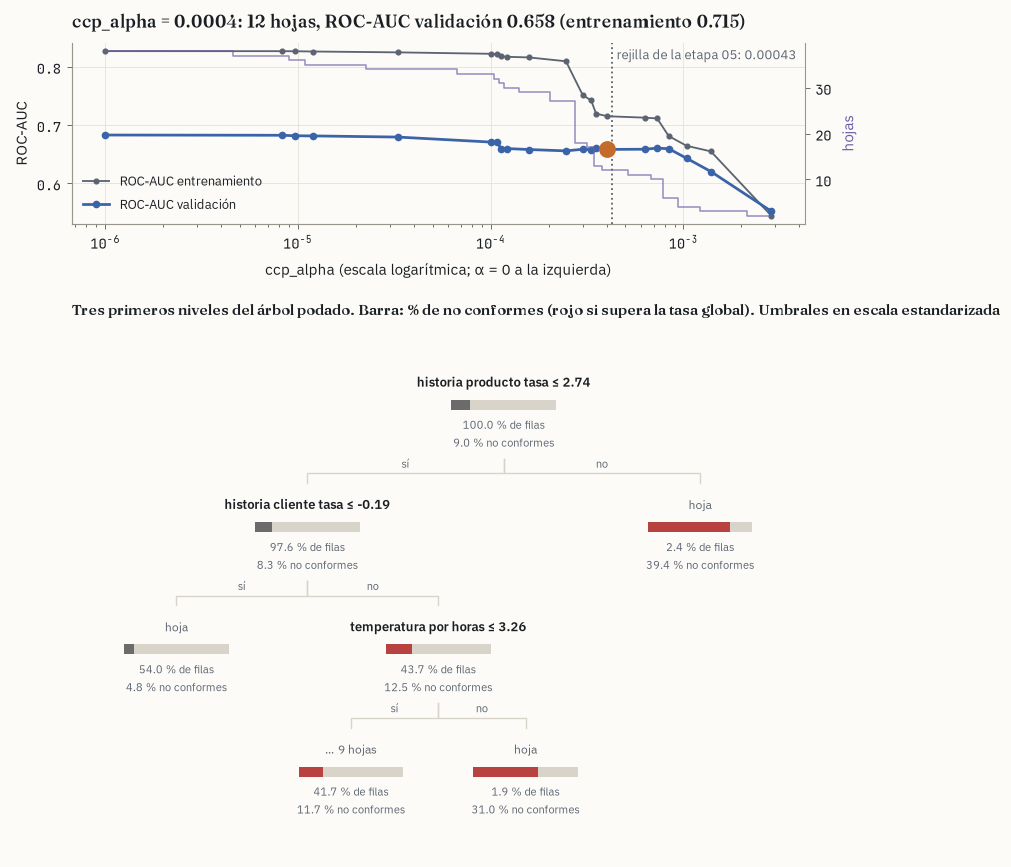

In [16]:
mostrar(ui.panel_arbol(d))    # poda ccp_alpha: hojas, ROC-AUC y el árbol que queda

In [17]:
p.diapositiva_red().mostrar()

**Del perceptrón al perceptrón multicapa.** Un perceptrón combina las entradas con unos pesos y aplica una
función de activación; el MLP apila una capa oculta de esas unidades antes de la salida logística:

$$\hat y = \varphi\big({\color{#6E5BA8}{w}}^\top x + {\color{#6E5BA8}{b}}\big)
\qquad\qquad
h = \mathrm{ReLU}\big({\color{#6E5BA8}{W_1}}\, x + {\color{#6E5BA8}{b_1}}\big), \quad
\hat p = {\color{#B8423F}{\sigma}}\big({\color{#6E5BA8}{w_2}}^\top h + {\color{#6E5BA8}{b_2}}\big)$$

**Retropropagación.** La red mide la pérdida logarítmica (con la penalización ${\color{#3B64A8}{\alpha}}$ sobre los
pesos), calcula su gradiente capa por capa con la regla de la cadena y mueve cada peso en contra de él:

$${\color{#6E5BA8}{W_1}} \leftarrow {\color{#6E5BA8}{W_1}} - \eta\,{\color{#B8423F}{\frac{\partial L}{\partial W_1}}},
\qquad
{\color{#B8423F}{\frac{\partial L}{\partial W_1}}} = \frac{\partial L}{\partial \hat p}\;
\frac{\partial \hat p}{\partial h}\;\frac{\partial h}{\partial W_1} + 2\,{\color{#3B64A8}{\alpha}}\,{\color{#6E5BA8}{W_1}}$$


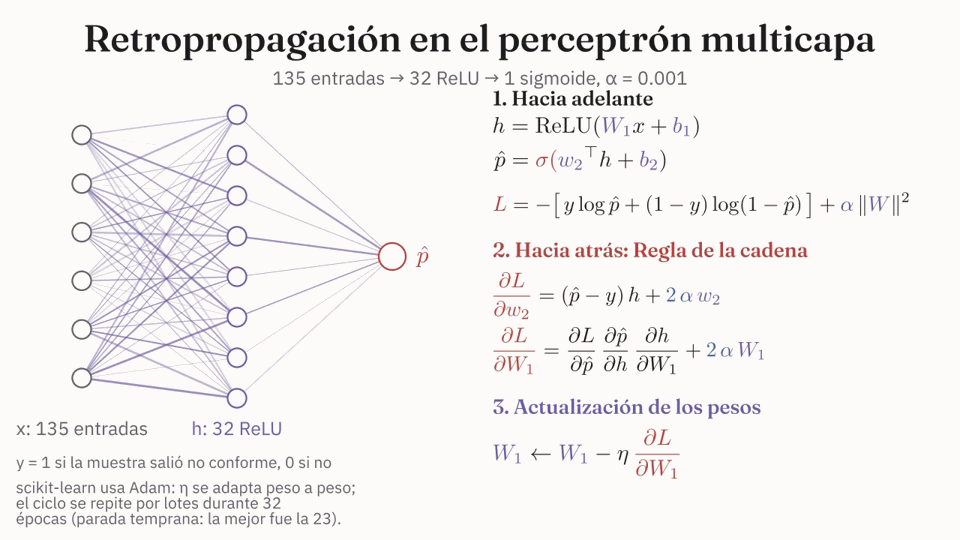

In [18]:
mostrar(g.video("red"))   # Manim: adelante, pérdida, gradientes hacia atrás y actualización (arquitectura real)

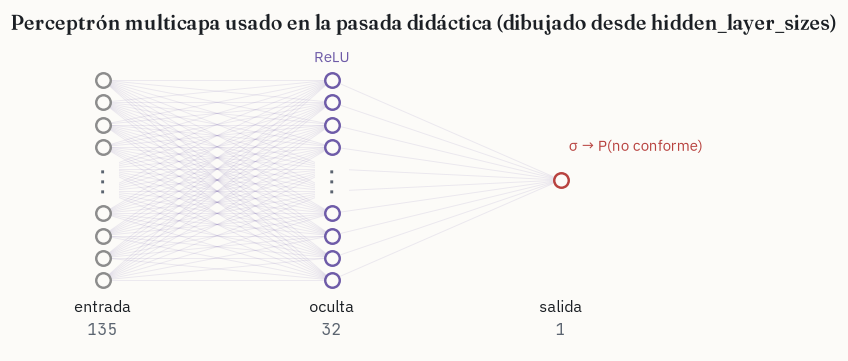

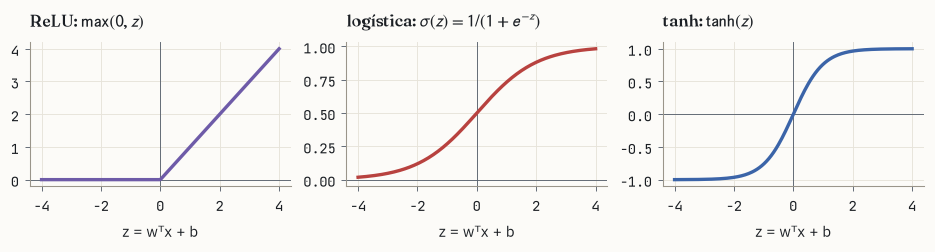

In [19]:
from proyecto.modelos import registro

red = registro.crear_modelo("clasificacion", "mlp")   # MLPClassifier con parada temprana
mostrar_figura(g.figura_arquitectura(d.mlp["n_entradas"], red.hidden_layer_sizes, red.activation))
mostrar_figura(g.figura_activaciones())

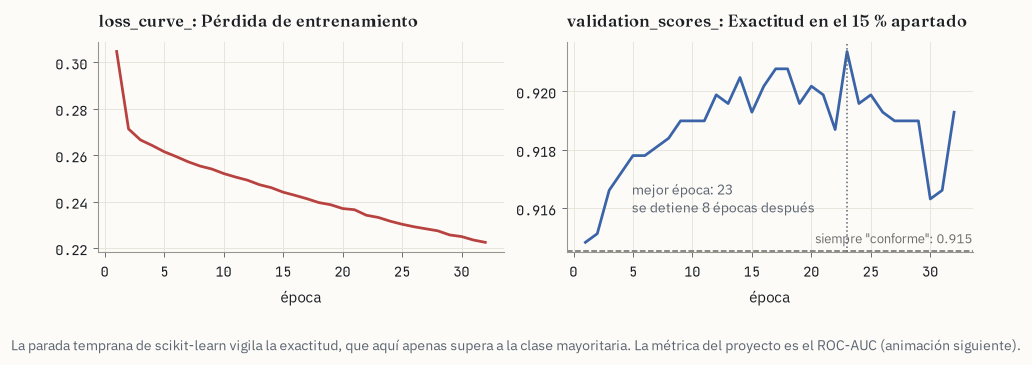

In [20]:
# Al construir: tuberia = construir_tuberia("clasificacion", "mlp", ...).fit(X_ent, y_ent); red = tuberia[-1]
curvas = g.figura_curva_perdida(d.mlp_perdida, d.mlp_validacion, d.mlp["paciencia"], d.mlp["fraccion_validacion"],
                                d.mlp["tasa_mayoritaria"])   # la exactitud de responder siempre "conforme", como referencia
mostrar_figura(curvas)


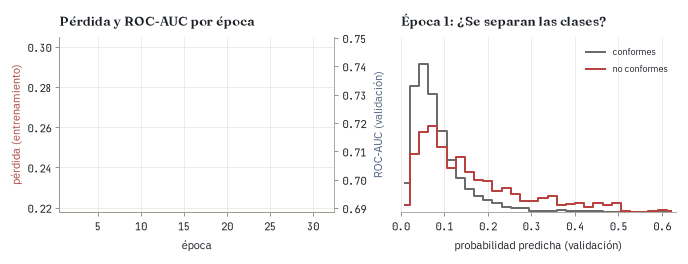
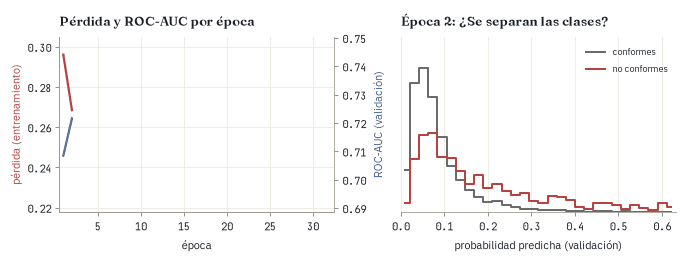
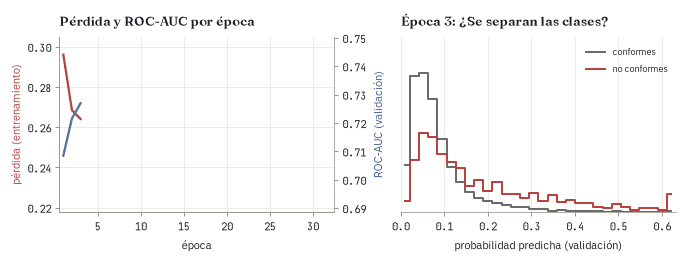
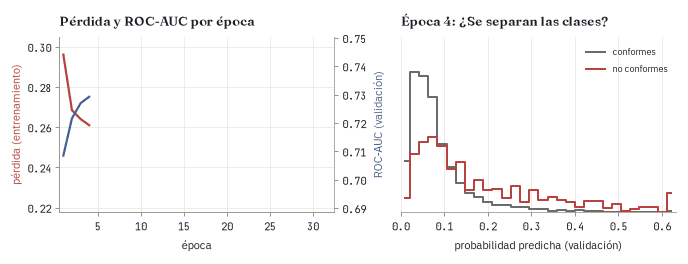
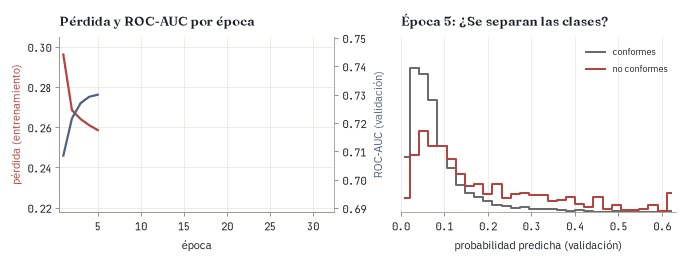
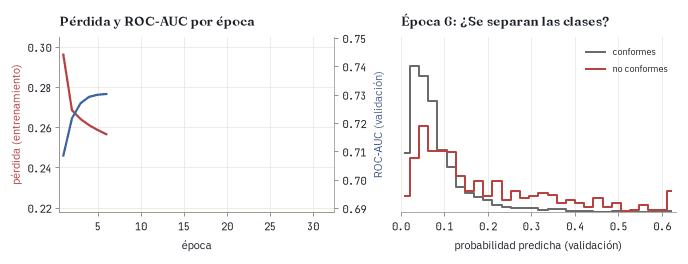
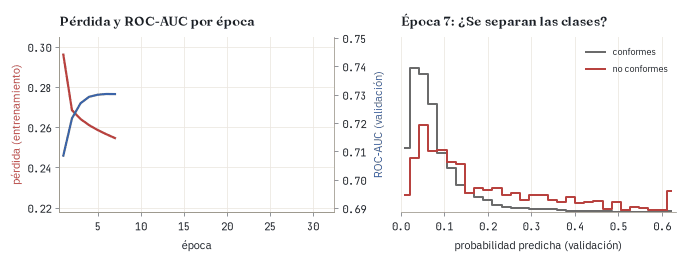
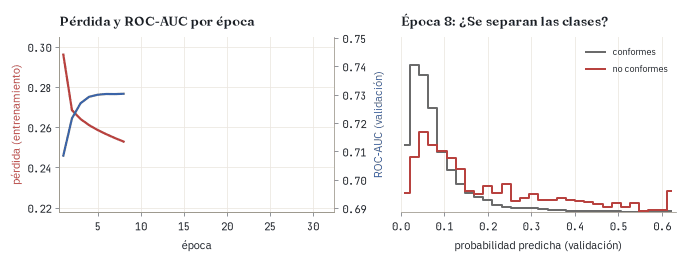
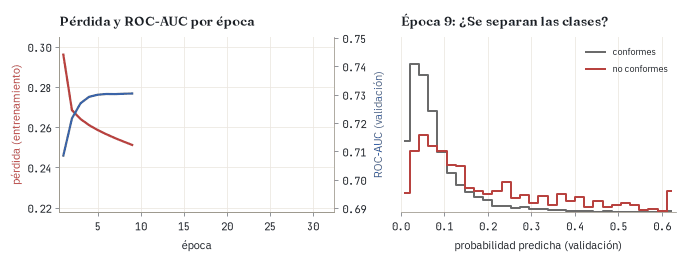
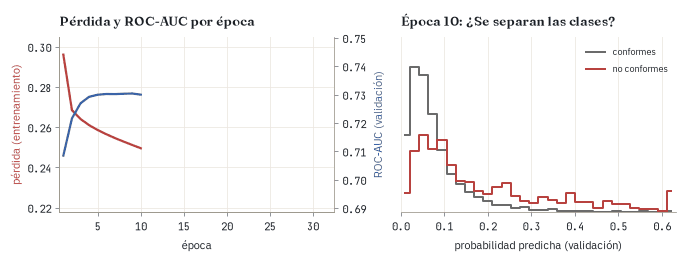
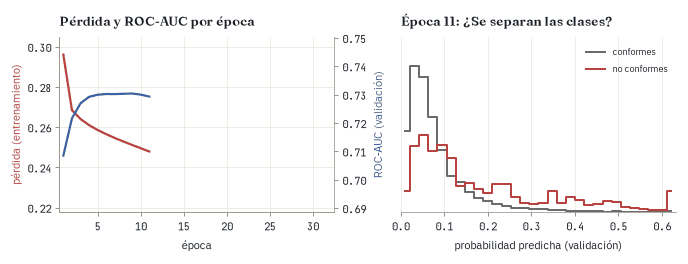
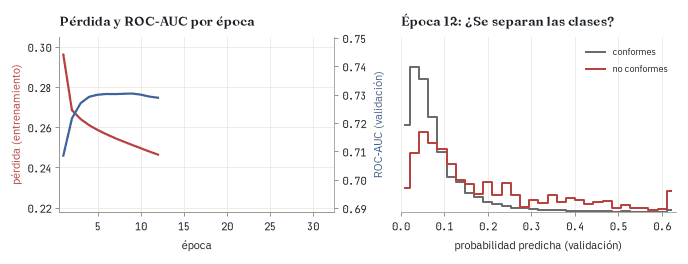
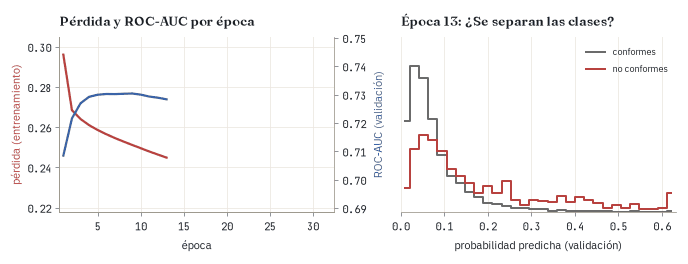
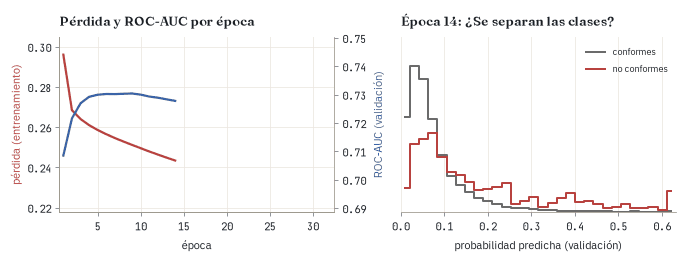
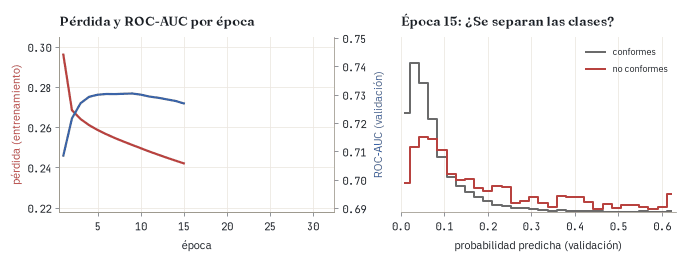
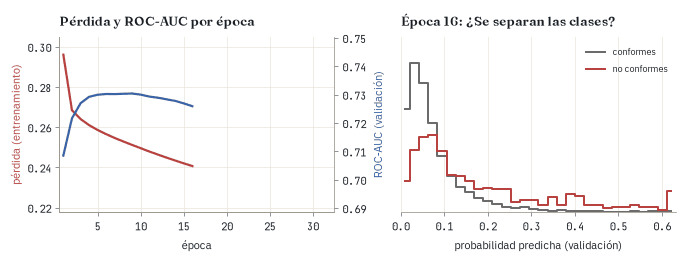
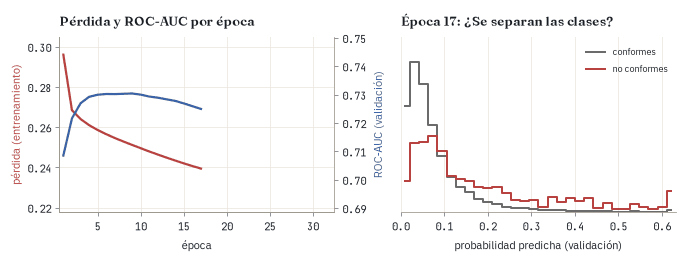
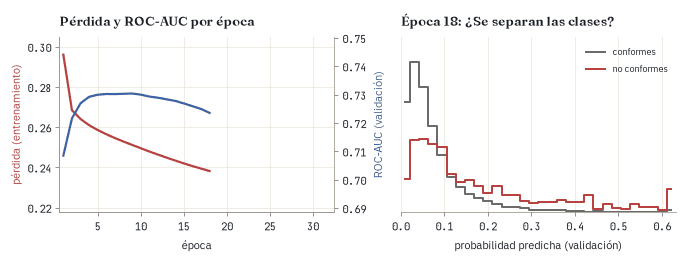
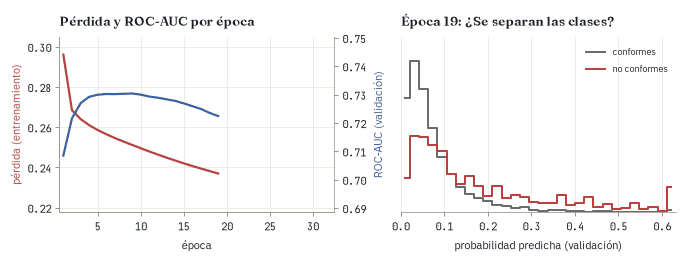
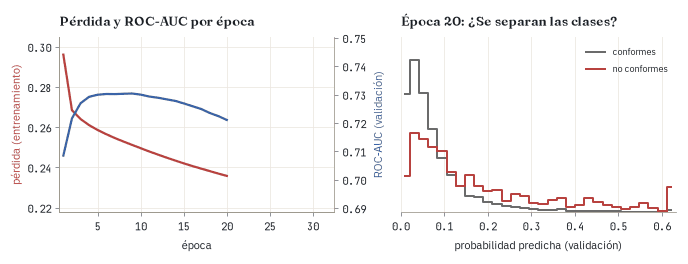
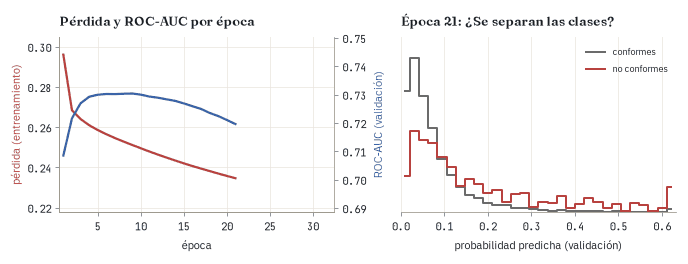
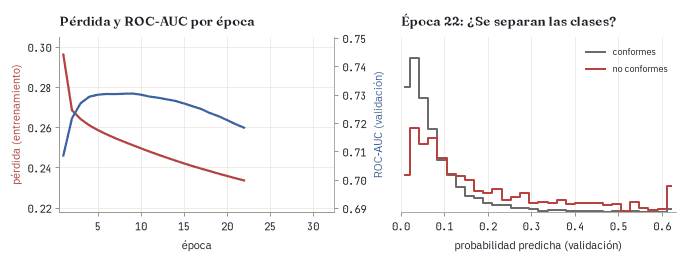
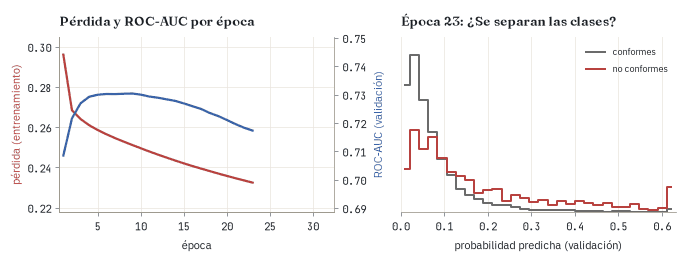
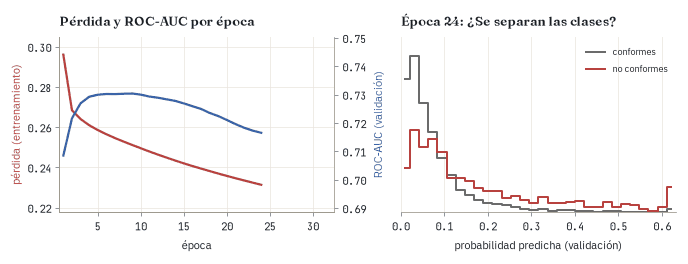
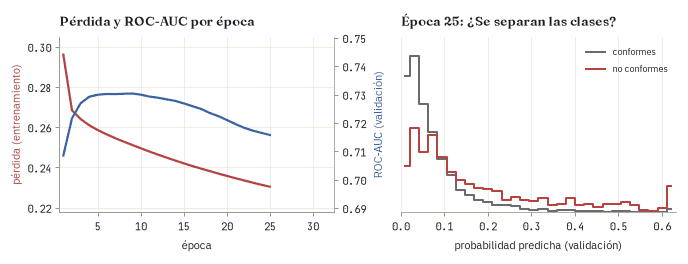
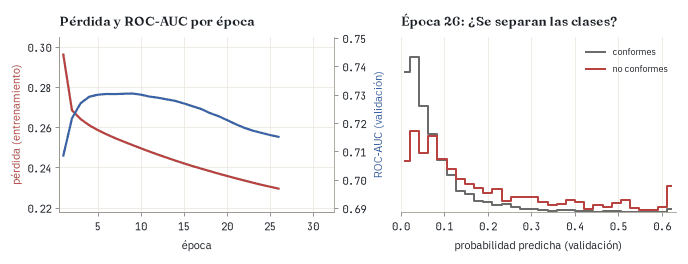
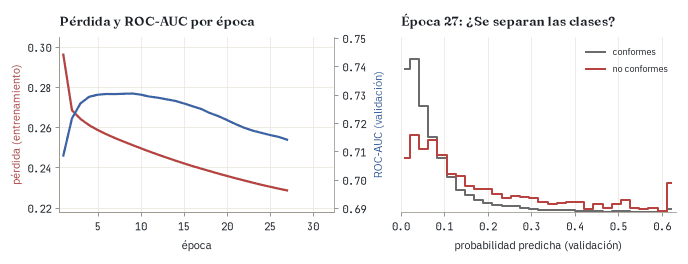
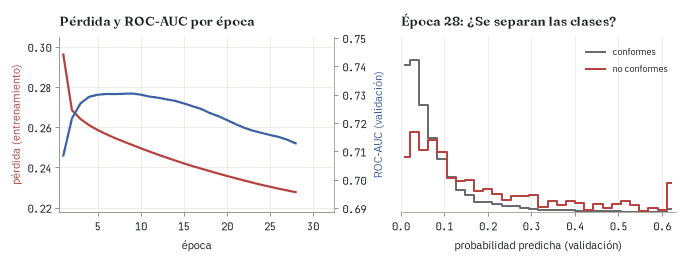
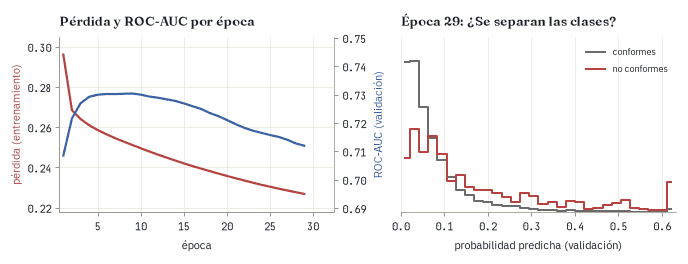
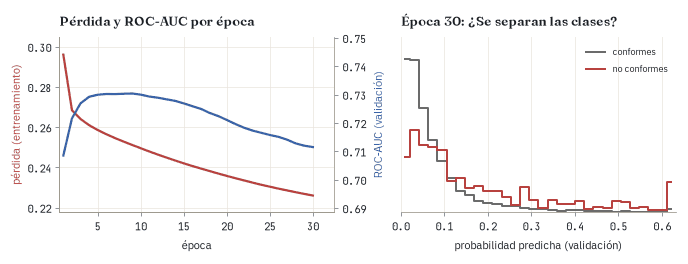
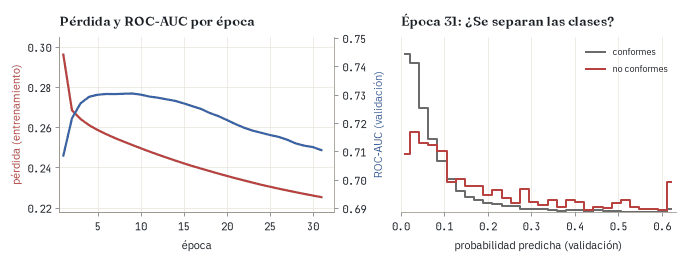
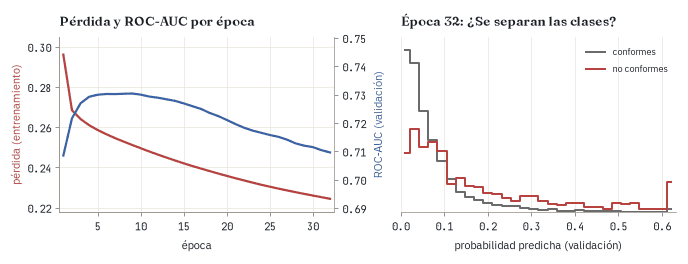

In [21]:
# La misma red, entrenada época por época con red.partial_fit(X_ent, y_ent) y evaluada en validación tras cada época
mostrar(g.animacion_red(d.red_perdida, d.red_auc, d.red_histogramas, d.red_bordes))

Panel interactivo: Ejecute la celda con el núcleo en marcha para mover los controles.

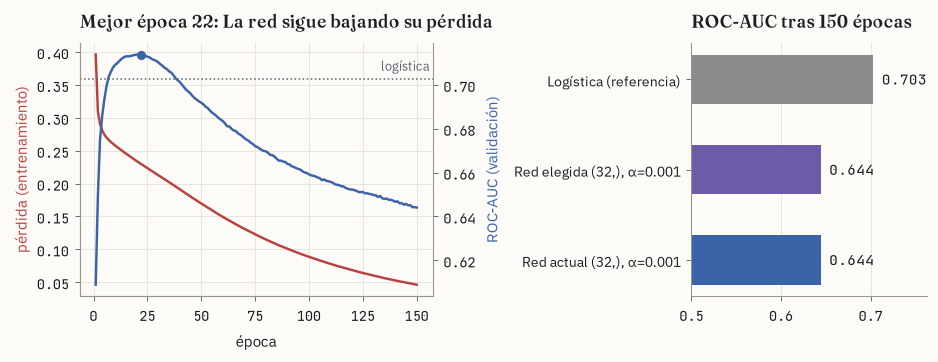

In [22]:
mostrar(ui.panel_red(d))      # capas ocultas y α: la red se reentrena en vivo sobre una submuestra fija

In [23]:
p.diapositiva_bayes().mostrar()

**Bayes en una línea.** De todos los positivos esperados, la fracción verdadera es la masa de
${\color{#2F8A4E}{\text{verdaderos positivos}}}$ sobre el total, que suma la masa de
${\color{#B8423F}{\text{falsos positivos}}}$; $S$ y $E$ salen de los controles de cada ensayo y
${\color{#3B64A8}{p}}$ es la probabilidad previa de contaminación:

$$\mathrm{VPP} = \frac{{\color{#2F8A4E}{S\,{\color{#3B64A8}{p}}}}}{{\color{#2F8A4E}{S\,{\color{#3B64A8}{p}}}}
+ {\color{#B8423F}{(1-E)(1-{\color{#3B64A8}{p}})}}}$$


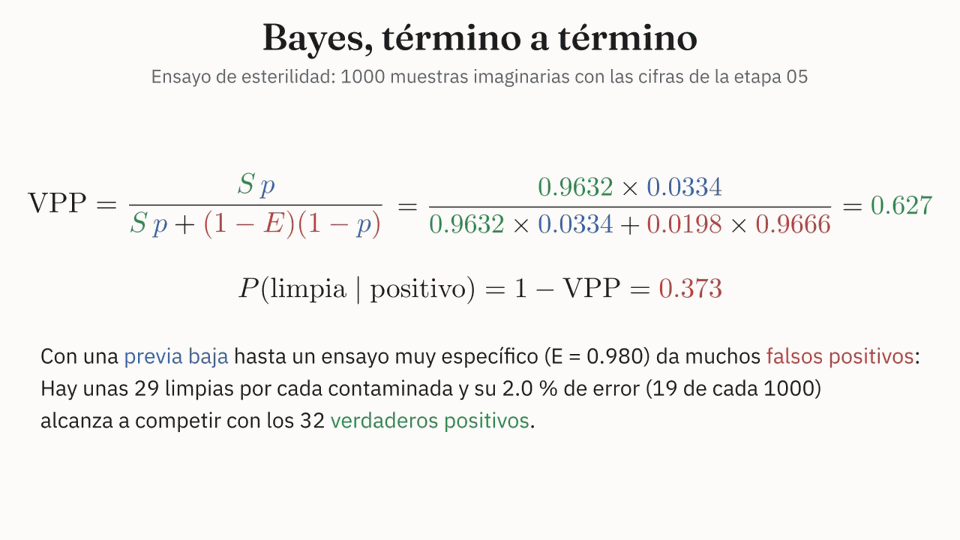

In [24]:
mostrar(g.video("bayes"))   # Manim: el árbol de 1000 muestras del ensayo de esterilidad se vuelve la fórmula

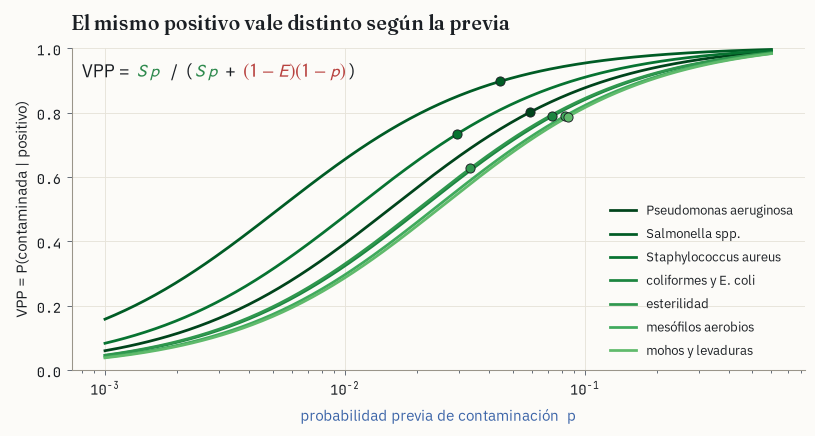

In [25]:
import numpy as np
from proyecto.evaluacion import bayes

ensayos = pd.DataFrame(clf["bayes"]["vpp_por_ensayo"])
previas = np.geomspace(1e-3, 0.6, 200)[:, None]   # rejilla de previas para dibujar
vpp = bayes.valor_predictivo_positivo(previas, ensayos["sensibilidad"].to_numpy(), ensayos["especificidad"].to_numpy())
observados = dict(zip(ensayos["ensayo"], zip(ensayos["prevalencia_corregida"], ensayos["vpp"])))
mostrar_figura(g.figura_vpp(previas[:, 0], vpp, ensayos["ensayo"].tolist(), observados))

Panel interactivo: Ejecute la celda con el núcleo en marcha para mover los controles.

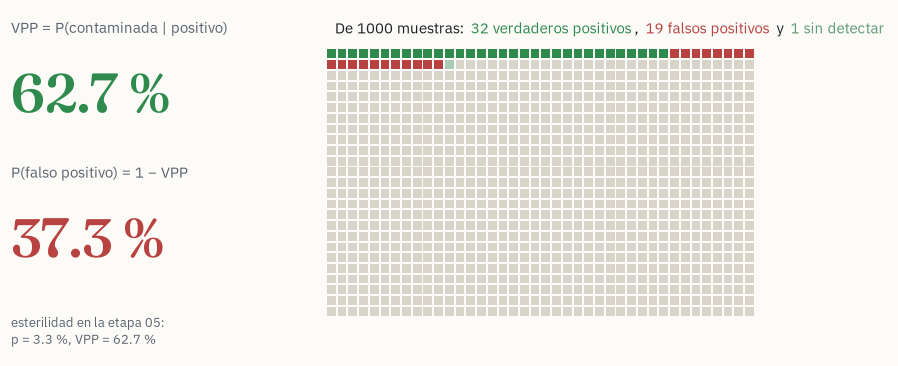

In [26]:
mostrar(ui.panel_bayes(d))    # previa, sensibilidad y especificidad → VPP y falsos positivos de cada 1000

In [27]:
p.diapositiva_agrupamiento().mostrar()

Segmento de clientes,Clientes,% de muestras,% no conformes
Más no conformidad y más entregas tardías,31,11.4,21.2
Más muestreo en planta y más tamaño de lote,73,73.6,7.1
Menos volumen mensual y menos muestreo en planta,82,15.0,6.9



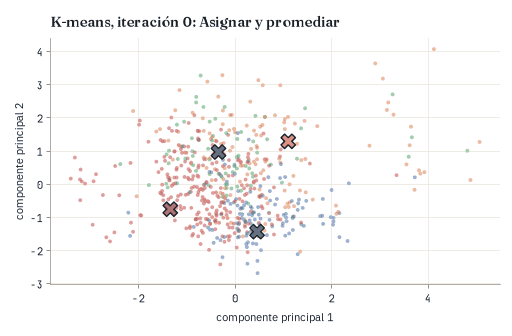
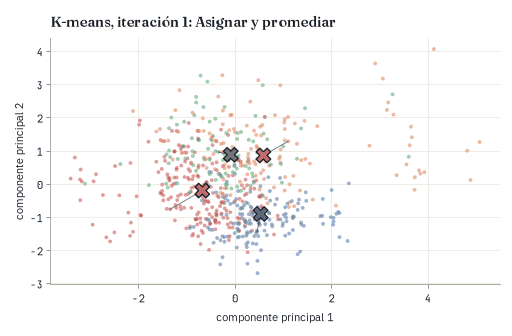
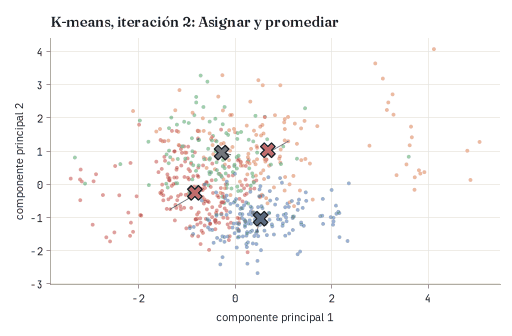
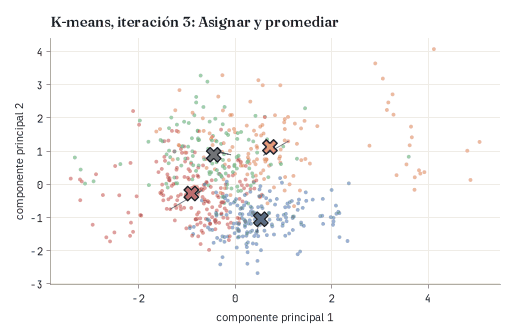
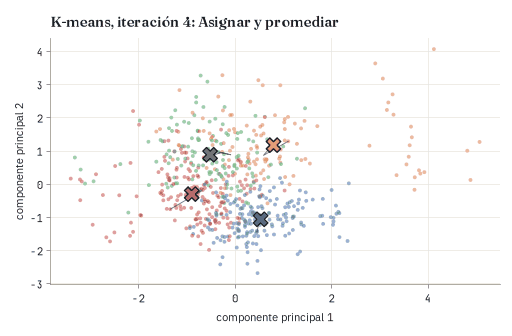
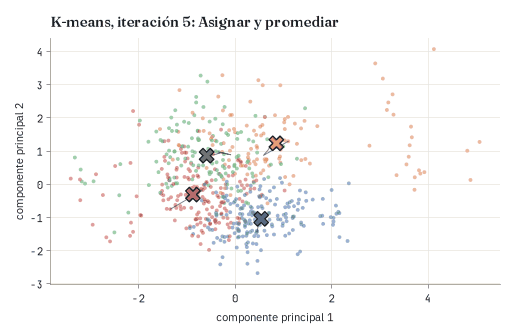
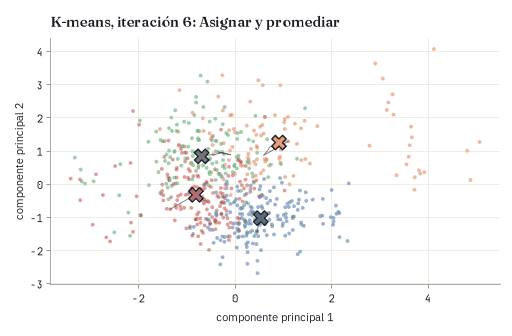
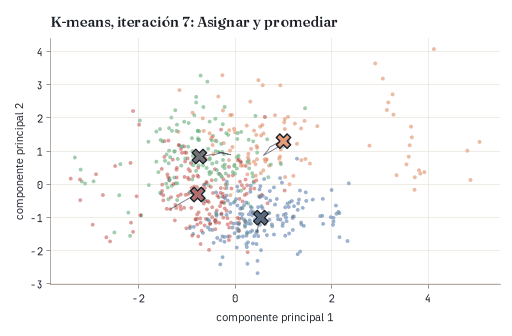
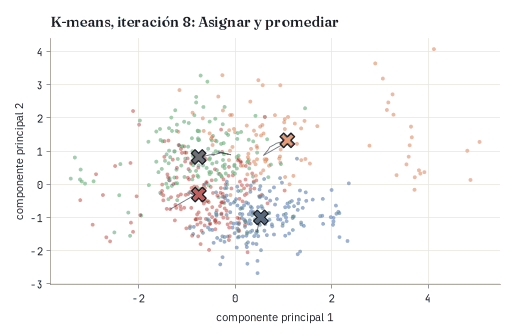
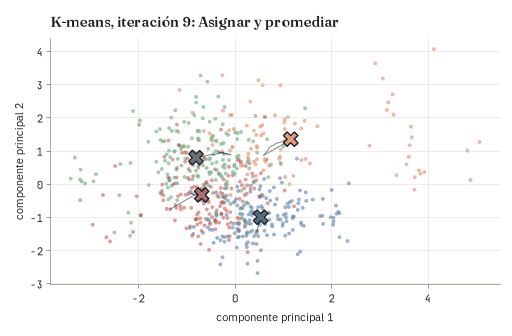
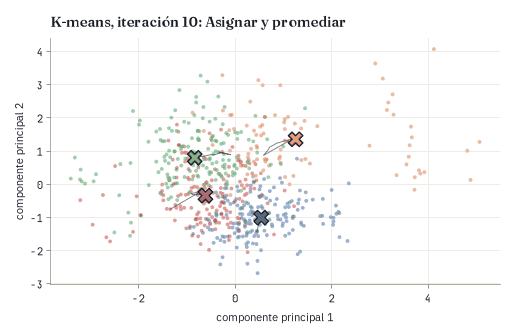
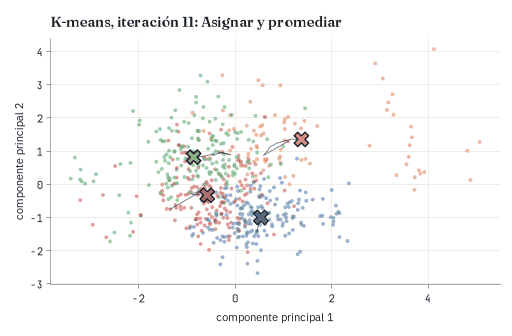
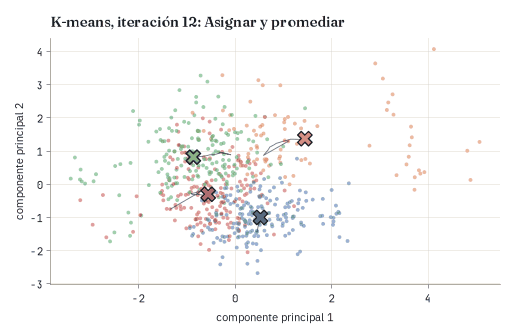
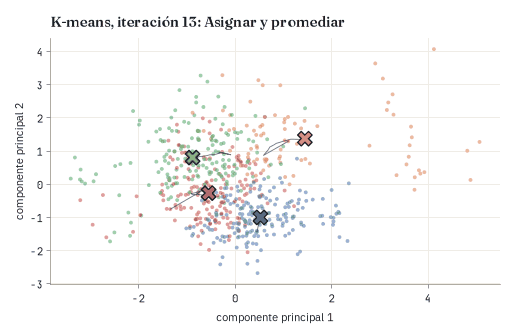
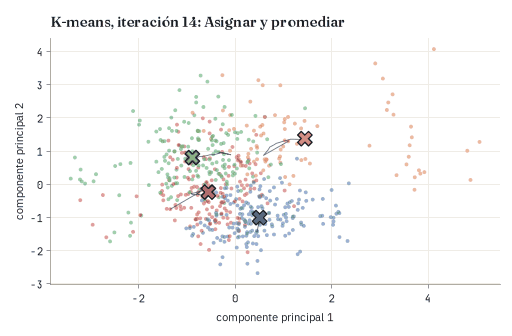
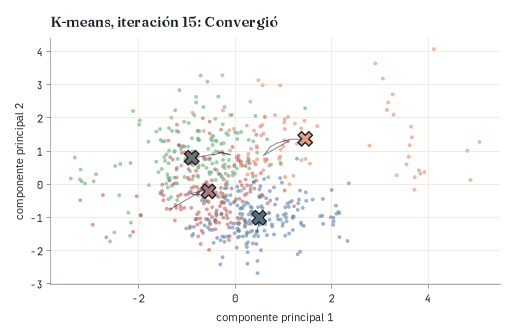

In [28]:
from proyecto.modelos.agrupamiento import pasos_kmeans

# K-means desde cero sobre una muestra de los perfiles: asignar al centro más cercano y promediar, hasta que nada cambie
centros, etiquetas = pasos_kmeans(d.kmeans_muestra, d.kmeans["k"])
plano = (d.kmeans_muestra - d.kmeans_media) @ d.kmeans_componentes.T   # proyección en dos componentes principales
mostrar(g.animacion_kmeans(plano, etiquetas, (centros - d.kmeans_media) @ d.kmeans_componentes.T))

Panel interactivo: Ejecute la celda con el núcleo en marcha para mover los controles.

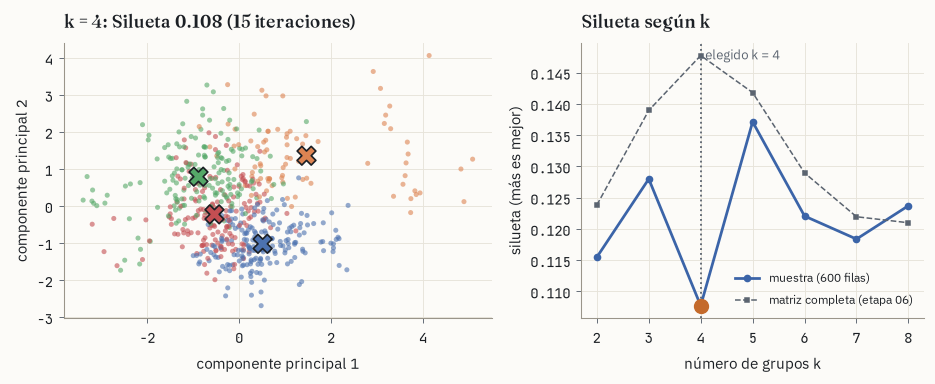

In [29]:
mostrar(ui.panel_kmeans(d))   # número de grupos k: silueta y nube en dos componentes

In [30]:
p.diapositiva_conclusiones().mostrar()